In [ ]:
# MobileNetV2 extracts visual features from the image.
# The Dense layer receives those features and predicts probabilities for the four classes.
# The loss function measures how far the prediction is from the correct label.
# Backpropagation updates the trainable classification-head weights.
# The frozen MobileNetV2 weights stay unchanged.

In [ ]:
import time
import json
import mlflow

In [ ]:
# ml flow setup


import mlflow

mlflow.set_tracking_uri("https://billion-rides-keno-viewers.trycloudflare.com")

mlflow.set_experiment("NeuroVision_AI")

experiment = mlflow.get_experiment_by_name("NeuroVision_AI")


In [ ]:
from tensorflow.keras.applications import MobileNetV2

In [ ]:
# checkpoints folder
CHECKPOINT_DIR = "/home/user/Sync/backup/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [ ]:
# Model Architecture

def create_tumor_classifier():

    # define the input layer
    inputs = layers.Input(
        shape = (224,224,3),
        name = "mri_images"
    )
    
    # rescaling the images to -1 , 1 for MobileNetV2 (we can use process_input())
    # x new = 2 * x old - 1
    x = layers.Rescaling(
        scale = 2.0,
        offset = -1.0,
        name = 'mobilenet_preprocessing'
    )(inputs)

    #loading the pretrained MobileNetV2
    base_model = MobileNetV2( weights ='imagenet', include_top = False, input_shape =(224, 224, 3))

    # freeze the pretrained layers
    base_model.trainable = False

    # extract images features
    x = base_model(x, training=False)


    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    
    outputs = layers.Dense(4, activation='softmax', name='Classification')(x)

    # Assemble the model

    model = Model(
        inputs = inputs,
        outputs = outputs
    )

    return model, base_model




In [ ]:
model, base_model = create_tumor_classifier()

model.summary()

base_model.summary()



In [29]:
# compile the model 

model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate =0.001 ), # Adam: updates the trainable weights.
    loss= 'categorical_crossentropy',
    metrics = ['accuracy']
)


In [30]:
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(CHECKPOINT_DIR, 'mobilenetv2_best.keras'),
    monitor = 'val_loss',
    save_best_only = True,
    mode = 'min',
    verbose = 1
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 3,
    restore_best_weights = True,
    verbose = 1
)


In [42]:
#training with tracking with mlflow
EPOCHS = 15
BATCH_SIZE = 32

with mlflow.start_run(run_name="MobileNetV2_Transfer_Learning"):

    # Track main parameters
    mlflow.log_param("epochs", EPOCHS)
    mlflow.log_param("batch_size", BATCH_SIZE)

    start_time = time.time()

    history = model.fit(
        train_dataset,
        validation_data = val_dataset,
        epochs = EPOCHS,
        callbacks = [
            checkpoint_callback,
            early_stopping_callback
        ]
    )

    # Track training duration
    mlflow.log_metric("training_time_seconds", time.time() - start_time)

    # Track best train results
    mlflow.log_metric(
            "best_train_accuracy",
            max(history.history["accuracy"])
        )
    mlflow.log_metric(
            "best_train_loss",
            min(history.history["loss"])
        )    

        # Track best validation results
    mlflow.log_metric(
            "best_val_accuracy",
            max(history.history["val_accuracy"])
        )
    mlflow.log_metric(
            "best_val_loss",
            min(history.history["val_loss"])
        )

     # Save the trained model as an MLflow model
    mlflow.tensorflow.log_model(
        model=model,
        name="model",
        registered_model_name="NeuroVision_MobileNetV2"
    )    

Epoch 1/15
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 2.3277e-04
Epoch 1: val_loss improved from 0.17898 to 0.15278, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 1.0000 - loss: 2.3295e-04 - val_accuracy: 0.9672 - val_loss: 0.1528
Epoch 2/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - loss: 1.5781e-04
Epoch 2: val_loss improved from 0.15278 to 0.14944, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 1.0000 - loss: 1.5780e-04 - val_accuracy: 0.9672 - val_loss: 0.1494
Epoch 3/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - loss: 1.0921e-04
Epoch 3: val_loss did not improve from 0.14944
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 1.0000 - loss: 1.0927e-04 - val_accuracy: 0.9715 - val_loss: 0.1511
Epoch 4/15
174/176 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accurac

2026/10/23 21:42:15 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
Successfully registered model 'NeuroVision_MobileNetV2'.
2026/10/23 21:42:26 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: NeuroVision_MobileNetV2, version 1
Created version '1' of model 'NeuroVision_MobileNetV2'.


🏃 View run MobileNetV2_Transfer_Learning at: https://billion-rides-keno-viewers.trycloudflare.com/#/experiments/1/runs/de8668db6aee4650a6d51c51a880d390
🧪 View experiment at: https://billion-rides-keno-viewers.trycloudflare.com/#/experiments/1


In [32]:
ARTIFACTS_DIR = "/home/user/Sync/backup/artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

with open(os.path.join(ARTIFACTS_DIR,"transfer_learning_history.json"), "w") as f:
    json.dump(history.history, f)

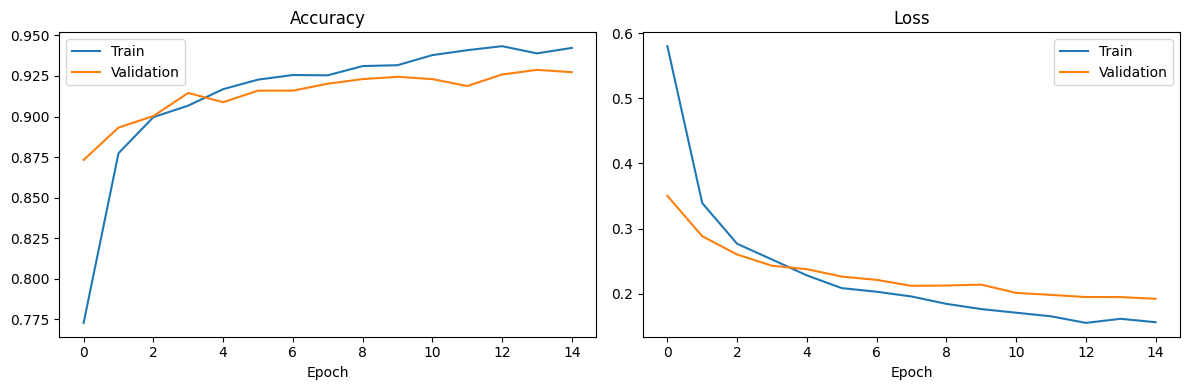

In [33]:
# plotting the history


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()